# Convolutional Neural Network (CNN) on Fashion MNIST Dataset

In this lab, we implement a **Convolutional Neural Network (CNN)** using TensorFlow / Keras.

#### CNN Architecture Components:
1. **Convolutional Layer (Conv2D)**: Extracts spatial patterns using learnable convolution kernels/filters.
2. **Activation (ReLU)**: Introduces non-linearity ($f(x) = \max(0, x)$).
3. **Max Pooling (MaxPooling2D)**: Reduces spatial dimensions, ensuring translation invariance.
4. **Dropout**: Regularization technique to prevent overfitting.
5. **Dense & Softmax**: Fully-connected classification layers.

### 1. Importing the necessary modules

In [1]:
import os, sys
# Fix for NVIDIA RTX 50-series (Blackwell CC 12.0) GPU autotuner
os.environ['TF_CUDNN_USE_AUTOTUNE'] = '0'
os.environ['TF_XLA_FLAGS'] = '--tf_xla_auto_jit=0'

cuda_bin = os.path.join(sys.prefix, 'lib', f'python{sys.version_info.major}.{sys.version_info.minor}', 'site-packages', 'nvidia', 'cuda_nvcc', 'bin')
if os.path.exists(cuda_bin):
    os.environ['PATH'] = cuda_bin + os.pathsep + os.environ.get('PATH', '')

import os, sys
# Prioritize virtual environment CUDA 12.9 compiler binaries for RTX 50-series (Blackwell)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

I0000 00:00:1789021663.642023   92474 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1789021663.671095   92474 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1789021664.496010   92474 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


### 2. Loading and Preprocessing Fashion MNIST for CNN

In [2]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Normalize pixel values to [0, 1]
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Reshape to (samples, height, width, channels)
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

# One-hot encode targets
num_classes = 10
y_train_cat = to_categorical(y_train, num_classes)
y_test_cat = to_categorical(y_test, num_classes)

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print(f"x_train shape: {x_train.shape}, y_train_cat shape: {y_train_cat.shape}")
print(f"x_test shape:  {x_test.shape},  y_test_cat shape:  {y_test_cat.shape}")

x_train shape: (60000, 28, 28, 1), y_train_cat shape: (60000, 10)
x_test shape:  (10000, 28, 28, 1),  y_test_cat shape:  (10000, 10)


### 3. Defining the CNN Architecture

In [3]:
cnn_model = Sequential([
    # Block 1
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    
    # Block 2
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    
    # Block 3
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    
    # Classification Head
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

cnn_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy'],
    jit_compile=False
)

cnn_model.summary()

/home/takrim/Desktop/ICE-M2012/.venv/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
W0000 00:00:1789021665.494494   92474 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1789021665.502549   92474 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1789021665.646525   92474 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1399 MB memory:  -> device: 0, name: N

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 1, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,474 (431.54 KB)

 Trainable params: 110,474 (431.54 KB)

 Non-trainable params: 0 (0.00 B)

### 4. Training the CNN Model

In [4]:
history = cnn_model.fit(
    x_train,
    y_train_cat,
    batch_size=128,
    epochs=5,
    validation_split=0.2,
    verbose=1
)

Epoch 1/5


I0000 00:00:1789021667.815653   92628 cuda_dnn.cc:461] Loaded cuDNN version 92501


375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7058 - loss: 0.8253 - val_accuracy: 0.8134 - val_loss: 0.5134
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8141 - loss: 0.5196 - val_accuracy: 0.8367 - val_loss: 0.4420
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8392 - loss: 0.4512 - val_accuracy: 0.8375 - val_loss: 0.4196
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8541 - loss: 0.4071 - val_accuracy: 0.8615 - val_loss: 0.3705
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8656 - loss: 0.3755 - val_accuracy: 0.8616 - val_loss: 0.3634


### 5. Evaluating CNN Model Performance on Test Data

In [5]:
test_loss, test_accuracy = cnn_model.evaluate(x_test, y_test_cat, verbose=0)
print(f"CNN Test Loss:     {test_loss:.4f}")
print(f"CNN Test Accuracy: {test_accuracy * 100:.2f}%")

CNN Test Loss:     0.3785
CNN Test Accuracy: 86.11%


### 6. Visualizing Training Curves

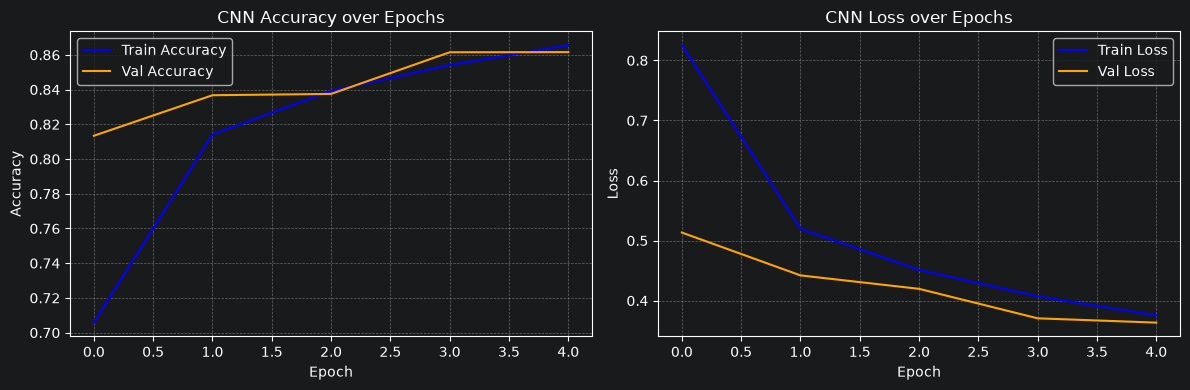

In [6]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', color='blue')
plt.plot(history.history['val_accuracy'], label='Val Accuracy', color='orange')
plt.title('CNN Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', color='blue')
plt.plot(history.history['val_loss'], label='Val Loss', color='orange')
plt.title('CNN Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 7. Predictions, Confusion Matrix, and Classification Report

In [7]:
y_pred_probs = cnn_model.predict(x_test)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_test_cat, axis=1)

cm = confusion_matrix(y_true, y_pred)
class_report_str = classification_report(y_true, y_pred, target_names=class_names)

print("Classification Report:")
print(class_report_str)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 712us/step
Classification Report:
              precision    recall  f1-score   support

 T-shirt/top       0.85      0.77      0.81      1000
     Trouser       0.99      0.95      0.97      1000
    Pullover       0.86      0.69      0.77      1000
       Dress       0.80      0.93      0.86      1000
        Coat       0.75      0.80      0.78      1000
      Sandal       0.96      0.97      0.96      1000
       Shirt       0.59      0.65      0.62      1000
     Sneaker       0.95      0.92      0.94      1000
         Bag       0.96      0.97      0.97      1000
  Ankle boot       0.93      0.96      0.95      1000

    accuracy                           0.86     10000
   macro avg       0.87      0.86      0.86     10000
weighted avg       0.87      0.86      0.86     10000



### 8. Visualizing Confusion Matrix Heatmap

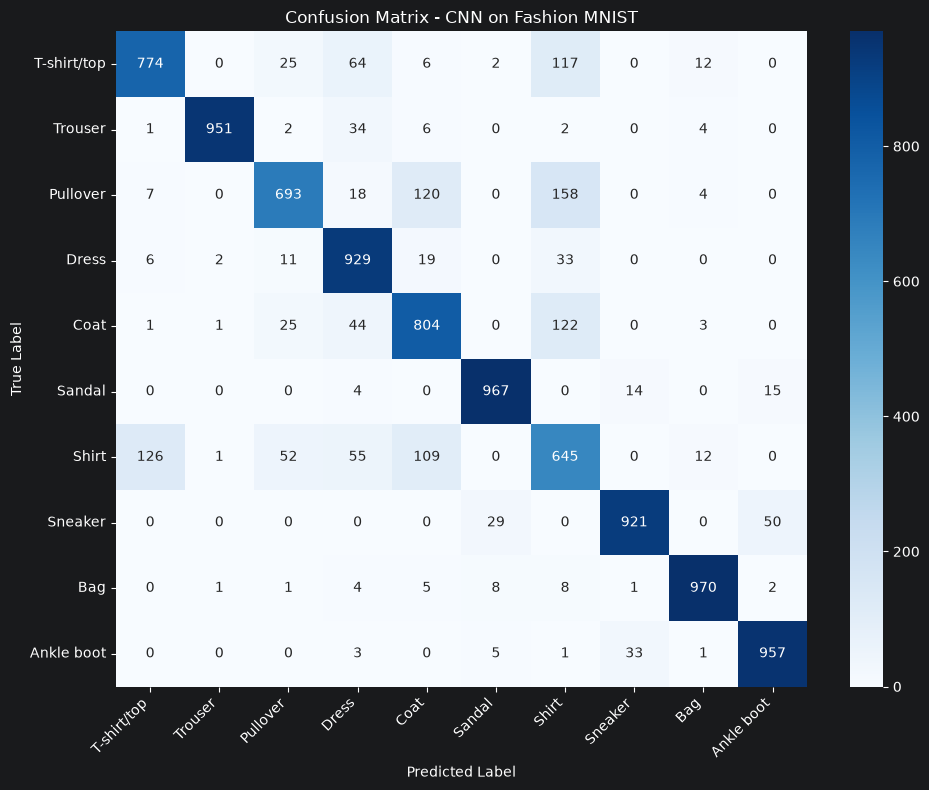

In [8]:
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - CNN on Fashion MNIST')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### 9. Visualizing Per-Class Performance Metrics (Precision, Recall, F1-Score)

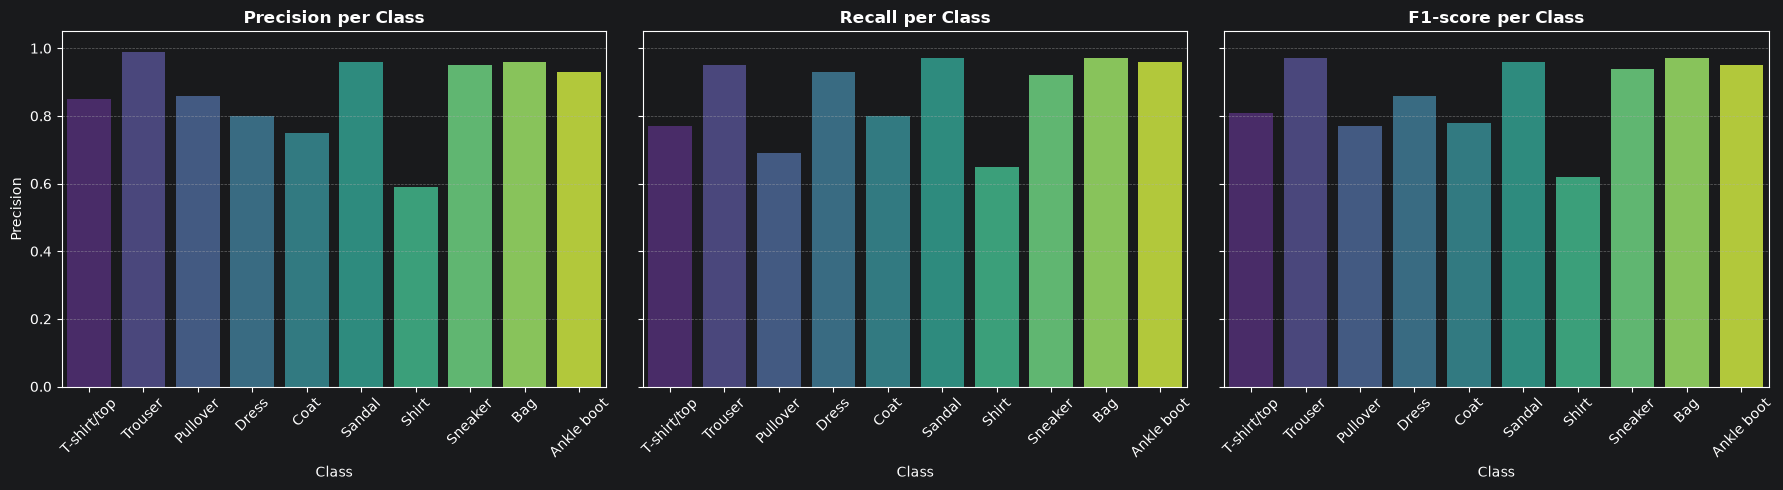

In [9]:
report_data = StringIO(class_report_str)
df_report = pd.read_csv(report_data, sep=r'\s{2,}', engine='python', index_col=0)
df_metrics = df_report.drop(columns=['support'], errors='ignore')
df_metrics = df_metrics.drop(['accuracy', 'macro avg', 'weighted avg'], errors='ignore')
df_metrics.index = class_names

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
metrics = ['precision', 'recall', 'f1-score']
palette = sns.color_palette('viridis', len(class_names))

for i, metric in enumerate(metrics):
    sns.barplot(x=df_metrics.index, y=df_metrics[metric], ax=axes[i], palette=palette, hue=df_metrics.index, legend=False)
    axes[i].set_title(f'{metric.capitalize()} per Class', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Class')
    axes[i].set_ylabel(metric.capitalize())
    axes[i].set_ylim(0, 1.05)
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].grid(True, linestyle="--", alpha=0.5, axis='y')

plt.tight_layout()
plt.show()